# Week 6: Decision Trees and Random Forests
**Victor Vasquez Gil** | Boston University | Integrated Capstone


### 1. Research Question

**Can a tree-based model improve default-risk ranking while keeping overfitting and false positives under control?**

My capstone proposal focuses on identifying charged-off Lending Club loans using information available at the time of issuance. This week compares a single decision tree against a random forest ensemble, using the Week 4 logistic regression specification as a baseline benchmark. The target remains binary: `Charged Off` is 1 and `Fully Paid` is 0, excluding all other interim loan statuses.

### Model Transparency vs. Predictive Power
There is a clear structural trade-off between these two approaches:
* **Single Decision Tree:** Provides explicit, readable decision paths that an underwriting analyst can directly inspect and follow.
* **Random Forest:** Combines predictions across an ensemble of trees to improve stability and performance, but loses the simple, single-rule explanation.

Rather than assuming the forest will automatically outperform the single tree, I want to evaluate what we actually gain and give up on this specific dataset.

In [1]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import sys, json, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1


In [3]:
SEED = 42
SAMPLE_SIZE = 50_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701  # Accepted-loans version 3; prevents accidental use of a partial export.
CV_FOLDS = 3
N_JOBS = 1
MODEL_TRAIN_SIZE = 8_000  # Weeks 5 and 6 use the same stratified training subset for a fair comparison.
DATA_PATH = None  # Or Path(r"/full/path/to/accepted_2007_to_2018Q4.csv.gz")
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATASET_VERSION = 3
OUTPUT_DIR = Path("week6_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
sns.set_theme(style="whitegrid", rc={"figure.dpi":120,"font.family":"DejaVu Sans",
    "axes.spines.top":False,"axes.spines.right":False,"grid.alpha":0.25})

In [4]:
def show_table(frame, decimals=3):
    formatters = {c: (lambda x: f"{x:,.{decimals}f}") for c in frame.select_dtypes(include="floating").columns}
    display(HTML('<style>.cap-table{border-collapse:collapse;font-family:system-ui;font-size:13px;}'
        '.cap-table th{background:#172B4D;color:white;padding:8px;}'
        '.cap-table td{padding:8px;border-bottom:1px solid #ddd;}'
        '.cap-table tr:nth-child(even){background:#f3f6f8;}</style>' +
        frame.to_html(index=False, border=0, classes="cap-table", formatters=formatters)))

def finish(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def clean_number(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False), errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def locate_source(configured):
    if configured is not None:
        path = Path(configured).expanduser()
        if path.is_file(): return path
        raise FileNotFoundError(f"DATA_PATH does not exist: {path}. No download was attempted.")
    roots = [Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
             Path.cwd()/"data", Path.cwd(), Path.home()/"Downloads"]
    # Prefer the known version-3 cache and its compressed file when both copies exist.
    for root in roots:
        if not root.is_dir(): continue
        candidates = []
        for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
            candidates.extend(p for p in root.rglob(name) if p.is_file())
        if candidates:
            return sorted(set(candidates), key=lambda p: (not p.name.endswith(".gz"), str(p)))[0]
    raise FileNotFoundError("No local accepted-loans file found. Set DATA_PATH to your existing version-3 CSV/CSV.GZ. No download is included.")

def sample_loans(path, cohort):
    fingerprint = {"resolved_path":str(path.resolve()),"bytes":path.stat().st_size,
        "mtime_ns":path.stat().st_mtime_ns,"cohort":cohort,"seed":SEED,
        "sample_size":SAMPLE_SIZE,"chunk_size":CHUNK_SIZE,"algorithm":"priority-v1"}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR/f"{cohort}_{key}.csv.gz"
    info_file = CACHE_DIR/f"{cohort}_{key}.json"
    if cache_file.is_file() and info_file.is_file():
        info = json.loads(info_file.read_text())
        sample = pd.read_csv(cache_file, dtype="string")
        sample["source_row"] = pd.to_numeric(sample["source_row"]).astype("int64")
        if info["rows_scanned"] != EXPECTED_SOURCE_ROWS:
            raise ValueError("Cached source row count does not match the expected version-3 file.")
        if len(sample) != min(SAMPLE_SIZE, info["eligible_rows"]):
            raise ValueError("Incomplete sample cache: remove these two cache files and rerun.")
        print("Reusing the local sample cache.")
        return sample, info
    header = pd.read_csv(path, nrows=0)
    required = FEATURES + (["int_rate"] if cohort=="pricing" else ["loan_status"])
    absent = sorted(set(required)-set(header.columns))
    if absent: raise ValueError(f"Required columns missing: {absent}")
    requested = list(dict.fromkeys(FEATURES+["int_rate","loan_status","id","member_id","issue_d"]))
    requested = [c for c in requested if c in header.columns]
    rng = np.random.default_rng(SEED)
    sample = None
    scanned = eligible = 0
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                                             chunksize=CHUNK_SIZE, low_memory=False),1):
        chunk["source_row"] = np.arange(scanned, scanned+len(chunk))
        scanned += len(chunk)
        if cohort=="pricing":
            rate = clean_number(chunk["int_rate"])
            chunk = chunk.loc[rate.gt(0) & rate.lt(100)].copy()
        else:
            chunk["loan_status"] = chunk["loan_status"].str.strip()
            chunk = chunk.loc[chunk["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample,chunk],ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE,"_priority")
        if batch%20==0: print(f"Scanned {scanned:,} source rows...")
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Scanned {scanned:,} rows; expected {EXPECTED_SOURCE_ROWS:,} for version 3. Check for a partial/different file before continuing.")
    if sample is None or len(sample)<100: raise ValueError("Too few eligible rows.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint,"rows_scanned":scanned,"eligible_rows":eligible,"sample_rows":len(sample)}
    sample.to_csv(cache_file,index=False,compression="gzip")
    info_file.write_text(json.dumps(info,indent=2))
    return sample,info

def prepare_xy(loans, cohort):
    for key in ["id","member_id"]:
        if key not in loans: continue
        ids = loans[key].astype("string").str.strip().replace("",pd.NA).dropna()
        if len(ids) and ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits before running the analysis.")
    if "member_id" not in loans or loans["member_id"].isna().all():
        print("No usable borrower ID: repeated-borrower dependence remains a limitation.")
    X = loans[FEATURES].copy()
    for col in NUMERIC: X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("",pd.NA)
        X[col] = values.astype(object).where(values.notna(),np.nan)
    y = (clean_number(loans["int_rate"]).rename("interest_rate") if cohort=="pricing" else
         loans["loan_status"].str.strip().map({"Fully Paid":0,"Charged Off":1}).astype(int).rename("charged_off"))
    assert X.index.equals(y.index) and y.notna().all()
    return X,y

def make_preprocessor(columns=None, numeric_scale=True, scale_all=False):
    columns = FEATURES if columns is None else list(columns)
    transforms=[]
    for i,col in enumerate(columns):
        if col in NUMERIC:
            steps=[("impute",SimpleImputer(strategy="median",keep_empty_features=True))]
            if numeric_scale: steps.append(("scale",StandardScaler()))
        else:
            steps=[("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
                   ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))]
        transforms.append((f"g{i:02d}",Pipeline(steps),[col]))
    prepare=ColumnTransformer(transforms,remainder="drop",verbose_feature_names_out=True)
    return Pipeline([("columns",prepare),("scale",StandardScaler())]) if scale_all else prepare

def rmse(y,pred): return float(np.sqrt(mean_squared_error(y,np.asarray(pred).ravel())))

def regression_metrics(name, model, Xfit,yfit,Xhold,yhold):
    pred=np.asarray(model.predict(Xhold)).ravel()
    return {"Model":name,"Training RMSE":rmse(yfit,model.predict(Xfit)),"Test RMSE":rmse(yhold,pred),
            "Test MAE":mean_absolute_error(yhold,pred),"Test R2":r2_score(yhold,pred)}

def ranking_score(model,X):
    if hasattr(model,"decision_function"): return np.asarray(model.decision_function(X)).ravel()
    return model.predict_proba(X)[:,1]

def choose_threshold(target,scores,default):
    grid=np.unique(np.r_[default,np.quantile(scores,np.linspace(0.01,0.99,99))])
    table=pd.DataFrame([{"Threshold":float(t),"Precision":precision_score(target,scores>=t,zero_division=0),
        "Recall":recall_score(target,scores>=t,zero_division=0),"F1":f1_score(target,scores>=t,zero_division=0)} for t in grid])
    chosen=float(table.sort_values(["F1","Threshold"],ascending=[False,False]).iloc[0]["Threshold"])
    return chosen,table

def classification_metrics(name,target,scores,threshold,rule):
    pred=np.asarray(scores)>=threshold
    tn,fp,fn,tp=confusion_matrix(target,pred,labels=[0,1]).ravel()
    return {"Model":name,"Rule":rule,"Threshold":float(threshold),"Accuracy":accuracy_score(target,pred),
        "Balanced accuracy":balanced_accuracy_score(target,pred),"Precision":precision_score(target,pred,zero_division=0),
        "Recall":recall_score(target,pred,zero_division=0),"F1":f1_score(target,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(target,scores),"Average precision":average_precision_score(target,scores),
        "Flagged share":float(pred.mean()),"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn)}

def plot_ranking(target,score_dict,filename):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
    for (name,scores),color in zip(score_dict.items(),[TEAL,BLUE,ORANGE,PURPLE,GRAY]):
        fpr,tpr,_=roc_curve(target,scores)
        precision,recall,_=precision_recall_curve(target,scores)
        axes[0].plot(fpr,tpr,color=color,label=f"{name} ({roc_auc_score(target,scores):.3f})")
        axes[1].step(recall,precision,where="post",color=color,label=f"{name} ({average_precision_score(target,scores):.3f})")
    axes[0].plot([0,1],[0,1],ls="--",color=GRAY)
    axes[1].axhline(float(np.mean(target)),ls="--",color=GRAY,label=f"Prevalence ({np.mean(target):.3f})")
    axes[0].set(title="Test ROC curves (legend = AUC)",xlabel="False positive rate",ylabel="Recall",xlim=(0,1),ylim=(0,1.02))
    axes[1].set(title="Test precision-recall curves (legend = AP)",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
    for ax in axes: ax.legend(fontsize=8)
    finish(fig,filename)

def plot_confusions(target,scores,default,chosen,name,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for ax,t,label in [(axes[0],default,"Default"),(axes[1],chosen,"Validation-selected")]:
        ConfusionMatrixDisplay.from_predictions(target,scores>=t,labels=[0,1],display_labels=["Fully paid","Charged off"],
            values_format=",d",cmap="Blues",colorbar=False,ax=ax)
        ax.set_title(f"{label}: {t:.3f}");ax.grid(False)
    fig.suptitle(f"{name}: the cost of changing the threshold",fontweight="bold")
    finish(fig,filename)

## 2. Match the Earlier Risk Analysis

I maintain Week 4's 50,000 loan outcome sample and its 60/20/20 stratified split whenever the source file and settings align. To ensure a direct, head to head comparison with Week 5's SVM models, all fits are performed on the exact same fixed 8,000-loan stratified subset drawn from the 30,000-loan training pool. Validation and test sets retain 10,000 loans each, with unused training rows left completely out of the pipeline. Both notebooks output source-row split manifests to verify an exact row-level match.

### Sample Size Constraints and Logistic Baseline
* **Computational Scope:** Selecting an 8,000 loan training subset reflects a computational budget constraint for controlled cross-model benchmarking, not an assumption that tree-based algorithms perform better on small samples. A logical next step is refitting the winning architectures on the full training pool.
* **Logistic Benchmark Alignment:** The logistic baseline reported here is refit specifically on this shared 8,000-row subset—I do not treat it as identical to the full 30,000-row Week 4 model.

### Feature Pipeline and Preprocessing
The 15-predictor set aligns directly with earlier classification notebooks. To prevent target leakage and preserve the issuance time perspective, `int_rate`, `grade`, `subgrade`, `installment`, repayment totals, recoveries, and post-issuance credit metrics are excluded. 

* **Imputation & Encoding:** Missing numeric values are median imputed, and categorical variables are one-hot encoded within each cross-validation fold.
* **Standardization:** Tree models are scale-invariant and do not require feature standardization to evaluate split thresholds. However, the logistic benchmark retains numeric standardization.

### Testing Protocol
Because this historical holdout split was previously viewed in Week 4, all model selections and threshold choices are frozen before touching the test set. These results reflect a controlled comparative experiment on a reused split rather than an unobserved out-of-time test.

In [5]:
DATA_PATH=locate_source(DATA_PATH)
loans,source_info=sample_loans(DATA_PATH,"outcome")
X,y=prepare_xy(loans,"outcome")
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=0.25,stratify=y_dev,random_state=SEED)
if len(X_train)>MODEL_TRAIN_SIZE:
    fit_indices,_=train_test_split(X_train.index,train_size=MODEL_TRAIN_SIZE,stratify=y_train,random_state=SEED)
    X_fit,y_fit=X_train.loc[fit_indices],y_train.loc[fit_indices]
else:
    X_fit,y_fit=X_train.copy(),y_train.copy()
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert y_fit.value_counts().min()>=CV_FOLDS
cv_splits=list(StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED).split(X_fit,y_fit))
manifest=loans[["source_row"]].copy();manifest["split"]="training pool not used"
manifest.loc[X_fit.index,"split"]="model training / CV"
manifest.loc[X_val.index,"split"]="validation / thresholds"
manifest.loc[X_test.index,"split"]="test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)
split_table=pd.DataFrame([{"Split":name,"Loans":len(target),"Charged-off share":float(target.mean())}
    for name,target in [("Training pool",y_train),("Model training (subset of pool)",y_fit),
                        ("Validation",y_val),("Test",y_test)]])
show_table(split_table)
print(f"{len(X_train)-len(X_fit):,} training-pool loans are unused; they are not added to validation or test.")

Reusing the local sample cache.
No usable borrower ID: repeated-borrower dependence remains a limitation.


Split,Loans,Charged-off share
Training pool,30000,0.199
Model training (subset of pool),8000,0.199
Validation,10000,0.199
Test,10000,0.199


22,000 training-pool loans are unused; they are not added to validation or test.


## 3. What the Training Data Tells Me

I check the outcome balance and missingness across the training subset before moving into model fitting. Given the heavy class imbalance with fully paid loans far outnumbering charged-off loans—relying on standard accuracy alone will obscure missed defaults. The substantial overlap in FICO distributions also indicates that no single simple rule will perfectly separate these classes without errors on both sides.

### Model Evaluation Focus
To evaluate performance rigorously across the full probability range:
* **Primary Tuning Metric:** I use cross-validated ROC-AUC to drive model selection and hyperparameter tuning.
* **Secondary Ranking Context:** Average Precision (PR-AUC) provides crucial context on positive-class performance under class imbalance.
* **Operational Classification:** Precision and recall are evaluated at decision thresholds selected explicitly on validation data.

It is worth noting that these metrics measure statistical ranking ability and classification performance they do not represent direct estimates of dollar savings or net portfolio return from an underwriting policy change.

Feature,Missing (%)
emp_length,5.80
revol_util,0.05
loan_amnt,0.00
fico_range_low,0.00
open_acc,0.00
annual_inc,0.00


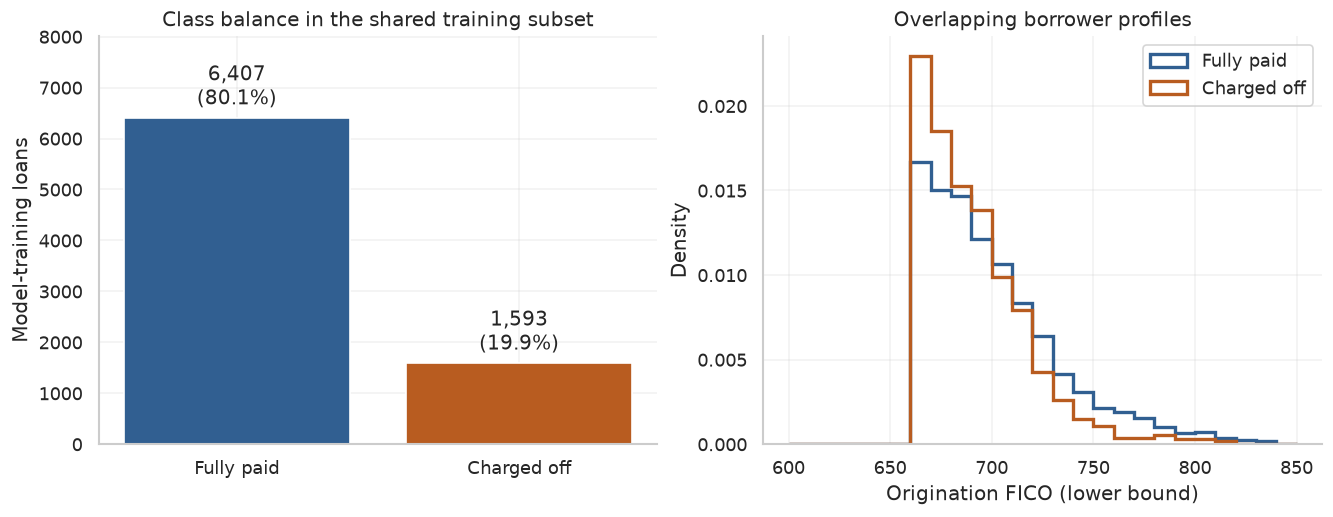

Charged-off loans make up **19.9%** of the model-training data. Predicting Fully Paid for every loan would be **80.1%** accurate and catch none of the charged-off loans. That is why I use ranking metrics and show precision and recall separately.

In [6]:
missing=X_fit.isna().mean().mul(100).rename("Missing (%)").rename_axis("Feature").reset_index().sort_values("Missing (%)",ascending=False)
show_table(missing.head(6),2)
fig,axes=plt.subplots(1,2,figsize=(11,4.2),layout="constrained")
counts=y_fit.value_counts().reindex([0,1])
bars=axes[0].bar(["Fully paid","Charged off"],counts,color=[BLUE,ORANGE])
axes[0].bar_label(bars,labels=[f"{v:,}\n({v/len(y_fit):.1%})" for v in counts],padding=4)
axes[0].set(ylim=(0,counts.max()*1.25),ylabel="Model-training loans",title="Class balance in the shared training subset")
for label,color,value in [("Fully paid",BLUE,0),("Charged off",ORANGE,1)]:
    axes[1].hist(X_fit.loc[y_fit.eq(value),"fico_range_low"].dropna(),bins=np.arange(600,856,10),density=True,
                 histtype="step",lw=2,color=color,label=label)
axes[1].set(xlabel="Origination FICO (lower bound)",ylabel="Density",title="Overlapping borrower profiles")
axes[1].legend()
finish(fig,"figure_1_training_eda")
display(Markdown(f"Charged-off loans make up **{y_fit.mean():.1%}** of the model-training data. "
    f"Predicting Fully Paid for every loan would be **{1-y_fit.mean():.1%}** accurate and catch none of the charged-off loans. "
    "That is why I use ranking metrics and show precision and recall separately."))

## 4. Entropy and Information Gain on an Actual Split

A decision tree splits observations into child nodes that are increasingly homogeneous in their target outcomes. For a given node with a charged-off proportion $p$, binary entropy (measured in bits) is calculated as:

$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$

where $0 \log_2(0)$ is defined as zero. The negative signs ensure that $H(p) \ge 0$, since the logarithm of any probability between $0$ and $1$ is negative. Entropy reaches its maximum at a balanced $50/50$ outcome mixture ($H=1$) and drops to zero for a completely pure node ($H=0$).

### Information Gain Calculation
When evaluating a candidate binary split into left ($L$) and right ($R$) child nodes, Information Gain measures the weighted reduction in entropy:

$$IG = H_{\text{parent}} - \frac{n_L}{n} H_L - \frac{n_R}{n} H_R$$

To ground this mechanism in our data, I fit a single-split decision tree (stump) on the training subset, compute the exact entropy reduction directly from the observed loan outcomes, and reconcile it against the fitted model's stored impurity metrics. This directly connects the theoretical formula to a concrete decision threshold in the Lending Club sample.

In [7]:
def tree_pipeline(estimator):
    return Pipeline([("prepare",make_preprocessor(numeric_scale=False)),("model",estimator)])
stump=tree_pipeline(DecisionTreeClassifier(criterion="entropy",max_depth=1,min_samples_leaf=5,random_state=SEED)).fit(X_fit,y_fit)
matrix=stump.named_steps["prepare"].transform(X_fit)
node_tree=stump.named_steps["model"].tree_
if node_tree.feature[0]<0: raise ValueError("The sample produced no usable root split.")
feature_index=int(node_tree.feature[0]);cutoff=float(node_tree.threshold[0])
root_feature=stump.named_steps["prepare"].get_feature_names_out()[feature_index].split("__",1)[-1]
left=matrix[:,feature_index]<=cutoff
def entropy(target):
    p=float(np.mean(target))
    return float(-sum(q*np.log2(q) for q in [p,1-p] if q>0))
parent_entropy=entropy(y_fit)
left_entropy=entropy(y_fit.iloc[np.flatnonzero(left)])
right_entropy=entropy(y_fit.iloc[np.flatnonzero(~left)])
weighted_children=float(left.mean()*left_entropy+(~left).mean()*right_entropy)
information_gain=parent_entropy-weighted_children
stored_gain=float(node_tree.impurity[0]-left.mean()*node_tree.impurity[node_tree.children_left[0]]-(~left).mean()*node_tree.impurity[node_tree.children_right[0]])
assert np.isclose(information_gain,stored_gain,atol=1e-10)
entropy_table=pd.DataFrame([{"Node":label,"Loans":len(target),"Charged-off share":float(target.mean()),"Entropy (bits)":entropy(target)}
    for label,target in [("Parent",y_fit),("Left",y_fit.iloc[np.flatnonzero(left)]),("Right",y_fit.iloc[np.flatnonzero(~left)])]])
show_table(entropy_table,4)
display(Markdown(f"The first split is **{root_feature} ≤ {cutoff:.3f}**. Parent entropy is {parent_entropy:.4f} bits, "
    f"weighted child entropy is {weighted_children:.4f}, and information gain is **{information_gain:.4f} bits**. "
    "This is the best eligible single split for this stump, not proof of a causal relationship."))
entropy_table.to_csv(OUTPUT_DIR/"root_entropy.csv",index=False)

Node,Loans,Charged-off share,Entropy (bits)
Parent,8000,0.1991,0.7202
Left,6070,0.1586,0.6311
Right,1930,0.3264,0.9112


The first split is **term_60 months ≤ 0.500**. Parent entropy is 0.7202 bits, weighted child entropy is 0.6987, and information gain is **0.0215 bits**. This is the best eligible single split for this stump, not proof of a causal relationship.

## 5. Control Tree Complexity and Compare a Forest

A fully grown decision tree will easily memorize individual training loans if left unconstrained. I include an unconstrained tree as an explicit overfitting diagnostic, along with a depth-2 tree as a simple reference point. Neither competes to be the final selected tree-family model they serve purely as analytical bounds.

### Decision Tree Tuning
The tuned decision tree uses entropy (Information Gain) as its split criterion and evaluates the following hyperparameter grid:

| Parameter | Values Searched | Practical Purpose |
| :--- | :--- | :--- |
| **`max_depth`** | $3, 6, 10$ | Limits the number of sequential decisions along any path |
| **`min_samples_leaf`** | $5, 50$ | Enforces a minimum count of training loans in every leaf node |
| **`min_samples_split`** | $2, 100$ | Requires sufficient loan volume before a node is permitted to split |

### Random Forest Mechanics
A random forest introduces two layers of variation bootstrap sampling of training rows and random feature subsets evaluated at each split. These two mechanisms decorrelate the individual trees. Averaging predictions across the ensemble can reduce overall variance, though higher performance on unobserved data is never guaranteed. In `scikit-learn` classification, the forest averages predicted class probabilities across all trees and assigns the class with the highest average probability.

### Ensemble Grid Search
For the random forest, I run a seeded search across 10 candidate configurations with bootstrap sampling enabled:
* **Estimator Count:** $150$ or $300$ trees
* **Tree Depth:** $6$, $12$, or unlimited (`None`)
* **Leaf & Split Thresholds:** `min_samples_leaf` $\in \{5, 20, 50\}$, `min_samples_split` $\in \{2, 100\}$
* **Feature Subsets:** `max_features` set to `"sqrt"` or $0.50$ (half of available features)

While adding trees can stabilize ensemble predictions, it increases computational runtime; depth and leaf controls remain essential to keep individual trees bounded.

### Selection and CV Protocol
I use 3-fold cross-validated ROC-AUC to select the optimal settings within each model class, then compare the top decision tree against the top random forest. Imputation and encoding are re-fit inside each fold to eliminate data leakage. The logistic benchmark relies on these exact same folds and source rows. The variance across CV folds is treated as descriptive context rather than statistical proof that minor metric differences are meaningful.

Tuning decision tree...


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Tuning random forest...


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Tuned tree selected settings: {'model__max_depth': 3, 'model__min_samples_leaf': 50, 'model__min_samples_split': 2}
Random forest selected settings: {'model__n_estimators': 150, 'model__min_samples_split': 100, 'model__min_samples_leaf': 20, 'model__max_features': 'sqrt', 'model__max_depth': None}
Comparing Depth-2 tree
Comparing Unrestricted tree


/tmp/ipykernel_25637/3663731750.py:36: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  for warning in caught: warnings.warn(str(warning.message),warning.category)


Comparing Matched logistic


/tmp/ipykernel_25637/3663731750.py:36: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  for warning in caught: warnings.warn(str(warning.message),warning.category)
/tmp/ipykernel_25637/3663731750.py:36: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  for warning in caught: warnings.warn(str(warning.message),warning.category)


Model,CV ROC-AUC,Fold SD,CV training AUC,CV AP
Tuned tree,0.6384,0.0050,0.6662,0.2867
Random forest,0.6826,0.0146,0.8066,0.3552
Depth-2 tree,0.6265,0.0160,0.6383,0.2758
Unrestricted tree,0.5494,0.0020,1.0000,0.2208
Matched logistic,0.6794,0.0170,0.7010,0.3512


Tree-family model selected before validation/test evaluation: Random forest


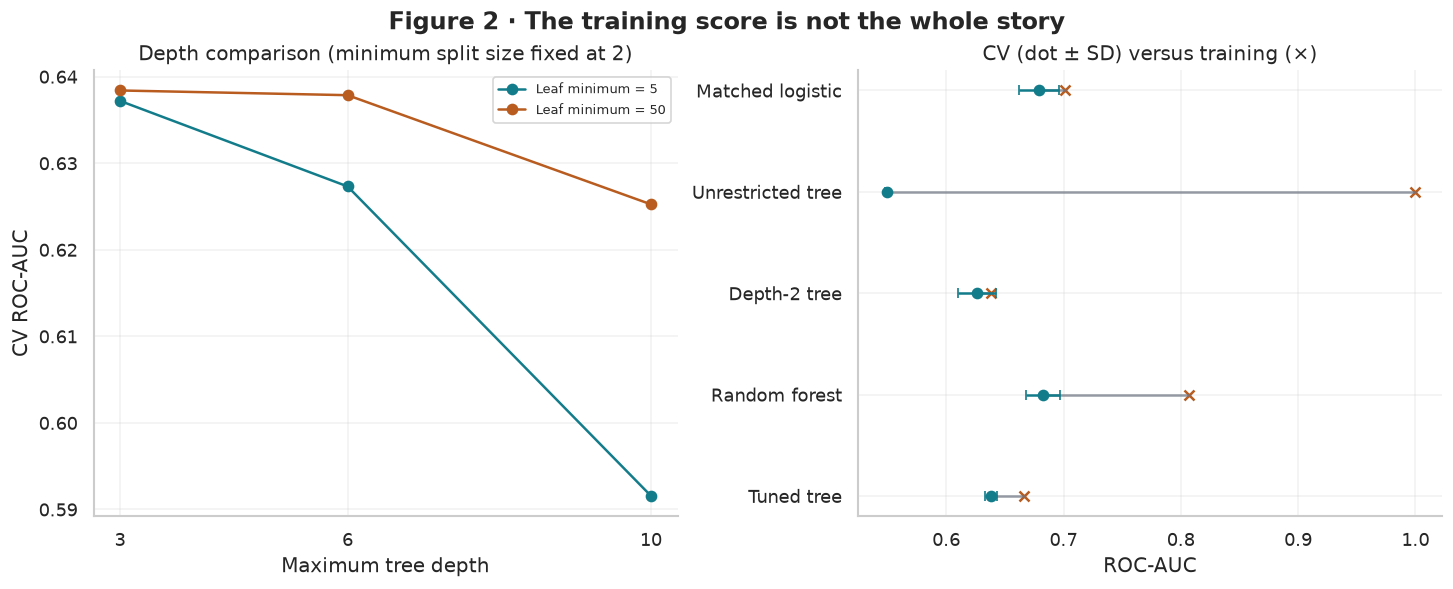

In [8]:
tree_base=tree_pipeline(DecisionTreeClassifier(criterion="entropy",random_state=SEED))
tree_grid={"model__max_depth":[3,6,10],"model__min_samples_leaf":[5,50],"model__min_samples_split":[2,100]}
print("Tuning decision tree...",flush=True)
tree_search=GridSearchCV(tree_base,tree_grid,scoring={"auc":"roc_auc","ap":"average_precision"},refit="auc",
    cv=cv_splits,n_jobs=N_JOBS,return_train_score=True,error_score="raise").fit(X_fit,y_fit)
forest_base=tree_pipeline(RandomForestClassifier(criterion="entropy",bootstrap=True,n_jobs=N_JOBS,random_state=SEED))
forest_grid={"model__n_estimators":[150,300],"model__max_depth":[6,12,None],
    "model__min_samples_leaf":[5,20,50],"model__min_samples_split":[2,100],"model__max_features":["sqrt",.5]}
print("Tuning random forest...",flush=True)
forest_search=RandomizedSearchCV(forest_base,forest_grid,n_iter=10,scoring={"auc":"roc_auc","ap":"average_precision"},
    refit="auc",cv=cv_splits,n_jobs=N_JOBS,random_state=SEED,return_train_score=True,error_score="raise").fit(X_fit,y_fit)

fitted={"Tuned tree":tree_search.best_estimator_,"Random forest":forest_search.best_estimator_}
cv_rows=[]
for name,search in [("Tuned tree",tree_search),("Random forest",forest_search)]:
    i=search.best_index_
    cv_rows.append({"Model":name,"CV ROC-AUC":float(search.best_score_),
        "Fold SD":float(np.std([search.cv_results_[f"split{k}_test_auc"][i] for k in range(CV_FOLDS)],ddof=1)),
        "CV training AUC":float(search.cv_results_["mean_train_auc"][i]),"CV AP":float(search.cv_results_["mean_test_ap"][i])})
    pd.DataFrame(search.cv_results_).to_csv(OUTPUT_DIR/f"{name.lower().replace(' ','_')}_cv_search.csv",index=False)
    print(name,"selected settings:",search.best_params_)
selected_name=max(cv_rows,key=lambda row:row["CV ROC-AUC"])["Model"]

diagnostics={"Depth-2 tree":tree_pipeline(DecisionTreeClassifier(criterion="entropy",max_depth=2,random_state=SEED)),
    "Unrestricted tree":tree_pipeline(DecisionTreeClassifier(criterion="entropy",random_state=SEED)),
    "Matched logistic":Pipeline([("prepare",make_preprocessor()),("model",LogisticRegression(C=10,max_iter=5000,solver="lbfgs",random_state=SEED))])}
for name,model in diagnostics.items():
    print("Comparing",name,flush=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always",ConvergenceWarning)
        scores=cross_validate(model,X_fit,y_fit,cv=cv_splits,scoring={"auc":"roc_auc","ap":"average_precision"},
            return_train_score=True,n_jobs=N_JOBS,error_score="raise")
        model.fit(X_fit,y_fit)
    if any(issubclass(w.category,ConvergenceWarning) for w in caught):
        raise RuntimeError(f"{name} did not converge. Resolve using training data before comparison.")
    for warning in caught: warnings.warn(str(warning.message),warning.category)
    fitted[name]=model
    cv_rows.append({"Model":name,"CV ROC-AUC":float(scores["test_auc"].mean()),"Fold SD":float(scores["test_auc"].std(ddof=1)),
        "CV training AUC":float(scores["train_auc"].mean()),"CV AP":float(scores["test_ap"].mean())})
cv_results=pd.DataFrame(cv_rows)
show_table(cv_results,4)
cv_results.to_csv(OUTPUT_DIR/"cv_comparison.csv",index=False)
print("Tree-family model selected before validation/test evaluation:",selected_name)

fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
raw=pd.DataFrame(tree_search.cv_results_)
for leaf,color in [(5,TEAL),(50,ORANGE)]:
    rows=raw.loc[raw.param_model__min_samples_leaf.astype(int).eq(leaf)&raw.param_model__min_samples_split.astype(int).eq(2)].sort_values("param_model__max_depth")
    axes[0].plot(rows.param_model__max_depth.astype(int),rows.mean_test_auc,"o-",color=color,label=f"Leaf minimum = {leaf}")
axes[0].set(title="Depth comparison (minimum split size fixed at 2)",xlabel="Maximum tree depth",ylabel="CV ROC-AUC",xticks=[3,6,10])
axes[0].legend(fontsize=8)
for i,row in cv_results.iterrows():
    axes[1].plot([row["CV ROC-AUC"],row["CV training AUC"]],[i,i],color=GRAY,alpha=.7)
    axes[1].scatter(row["CV training AUC"],i,marker="x",color=ORANGE)
    axes[1].errorbar(row["CV ROC-AUC"],i,xerr=row["Fold SD"],fmt="o",color=TEAL,capsize=3)
axes[1].set(yticks=range(len(cv_results)),yticklabels=cv_results.Model,xlabel="ROC-AUC",title="CV (dot ± SD) versus training (×)")
fig.suptitle("Figure 2 · The training score is not the whole story",fontweight="bold")
finish(fig,"figure_2_complexity_overfitting")

## 6. Look at the Rules and Feature Importance

I visualize only the first three levels of the tuned decision tree so that branch labels remain fully readable, with truncated branches extending beyond the displayed boundary. Thresholds are reported in original numeric units because tree-based models do not require feature standardization. Encoded categorical splits operate directly on binary indicator values.

### Evaluating Forest Feature Importance
For the random forest ensemble, I evaluate and compare two distinct measures of feature importance:

* **Impurity-Based Importance (MDI):** Sums the weighted impurity reductions (Gini/entropy drop) attributed to each feature across all trees, normalized to sum to 1. It reflects structural usage across the forest rather than simple split counts, though it naturally favors continuous variables and high-cardinality predictors with many possible split points.
* **Permutation Importance (MDA):** Measures the drop in validation ROC-AUC when a feature's values are randomly shuffled. To maintain pipeline integrity, I permute the original pre-encoded columns through the entire pipeline so all one-hot indicator columns belonging to a categorical feature drop out together. 

For computational efficiency, permutation importance is evaluated on a random subset of up to 2,000 validation rows across 3 repeats. Error bars depict variance across those repeats rather than formal confidence intervals. Note that correlated predictors can substitute for one another during shuffling, which may artificially mute individual permutation scores. Neither metric implies direct causal relationships.

### Methodological Integrity
These interpretability diagnostics are performed strictly after model parameters and hyperparameter choices are finalized. I do not use validation feature importance post-hoc to drop variables and then report the original validation metrics as if that feature selection step never occurred.

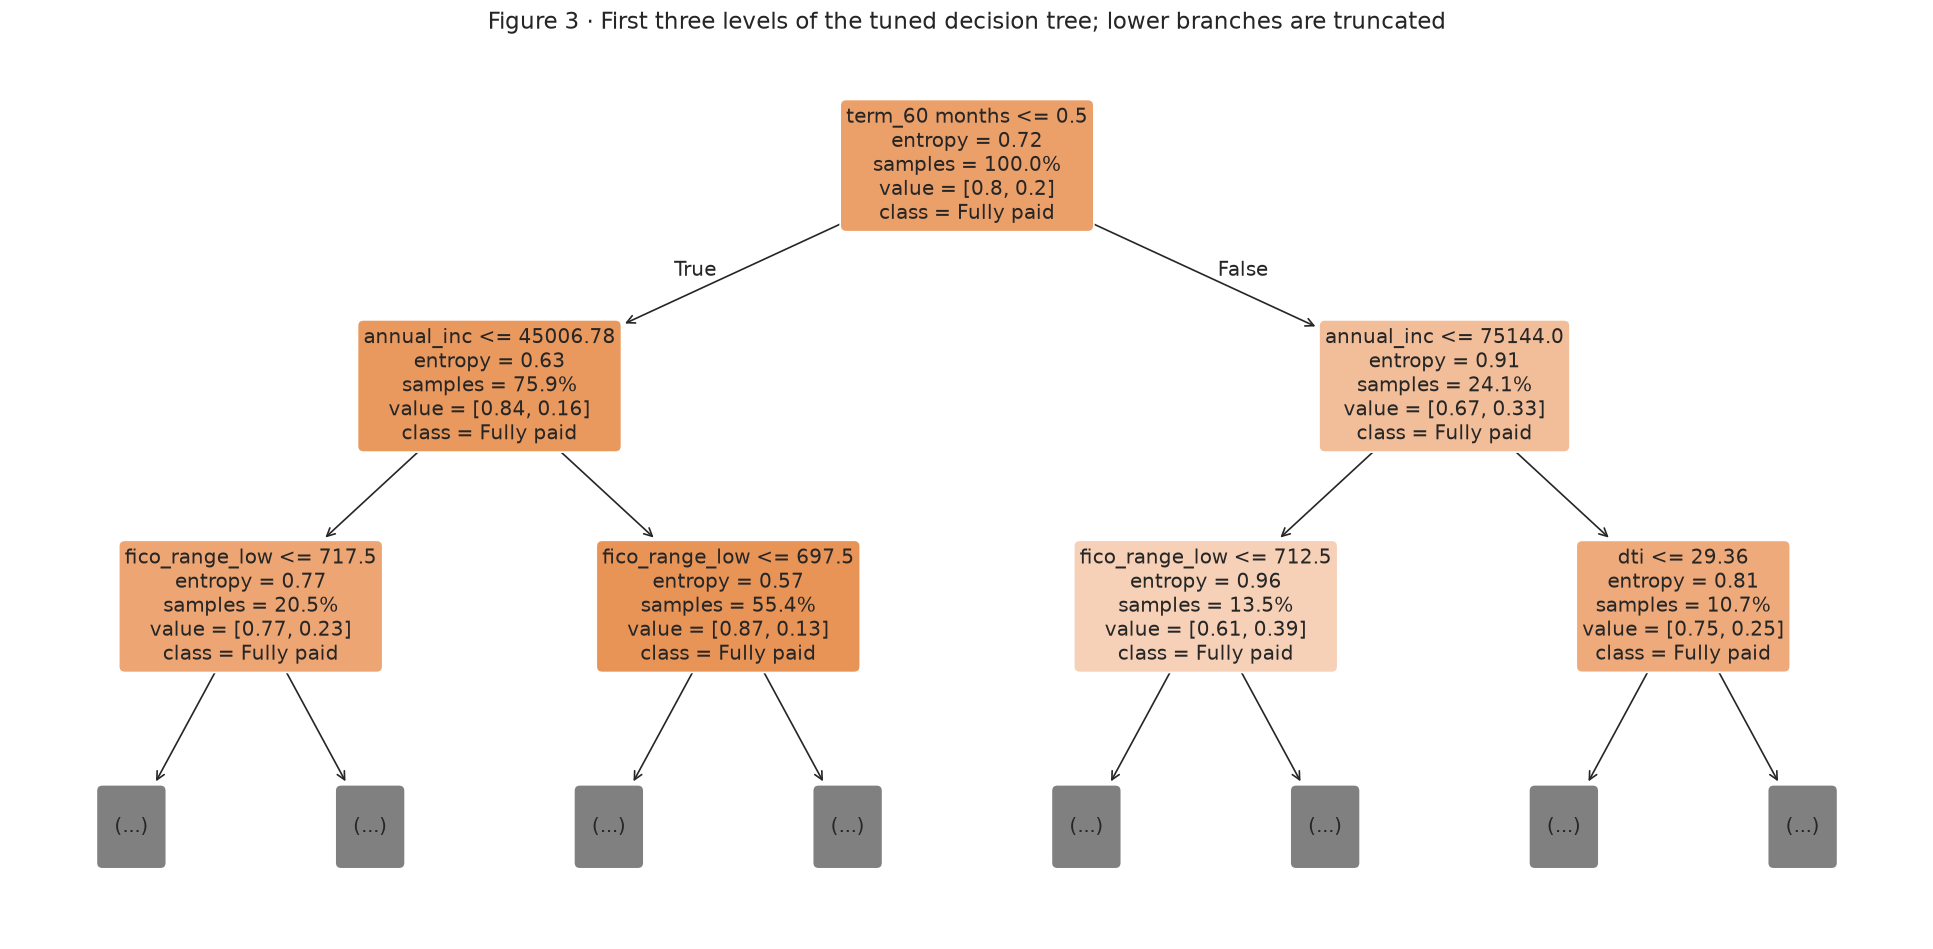

Feature,Impurity importance,Validation permutation AUC drop,Repeat SD
term,0.1670,0.0706,0.0059
fico_range_low,0.1127,0.0390,0.0080
dti,0.1228,0.0304,0.0052
annual_inc,0.1087,0.0227,0.0030
loan_amnt,0.0772,0.0216,0.0019
inq_last_6mths,0.0382,0.0148,0.0017
home_ownership,0.0359,0.0140,0.0020
purpose,0.0319,0.0129,0.0001
revol_bal,0.0729,0.0125,0.0019
emp_length,0.0370,0.0113,0.0004


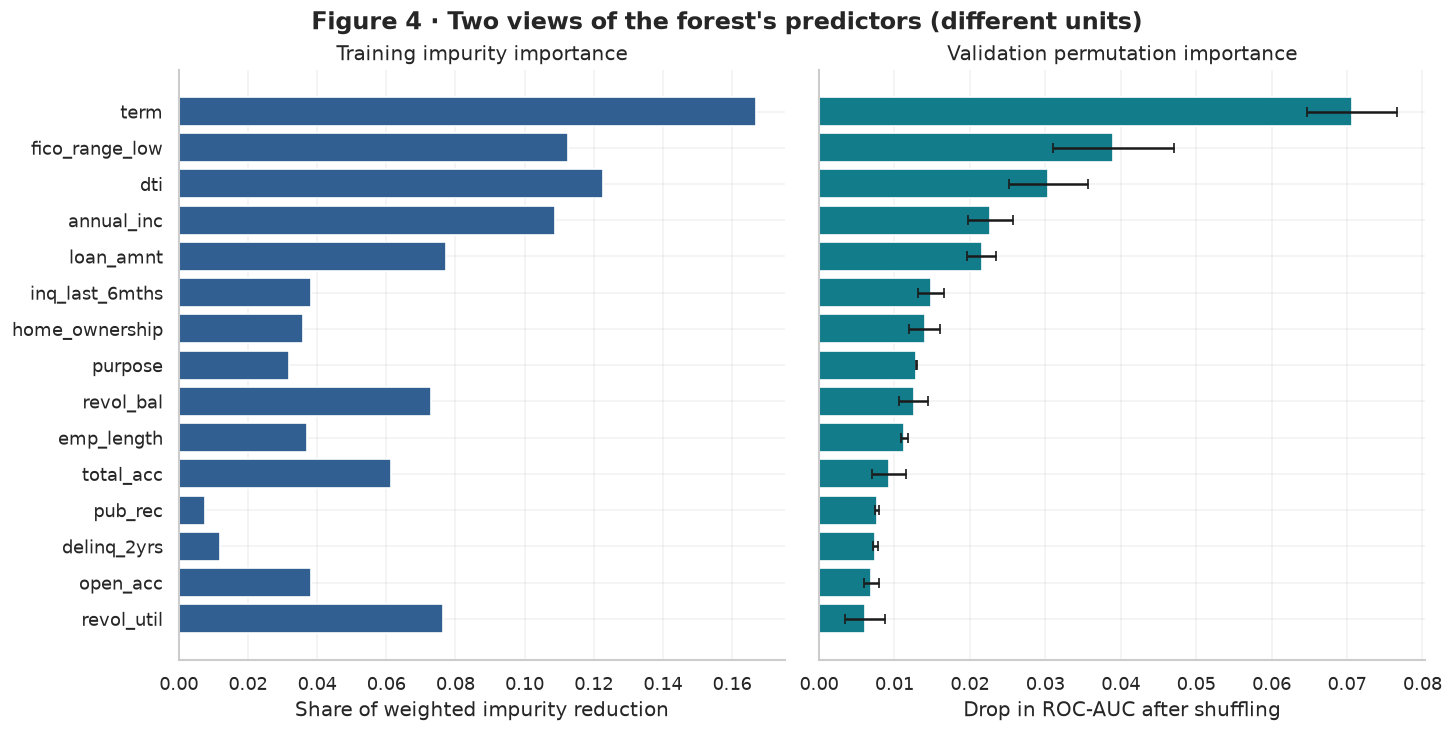

In [9]:
tuned_tree=fitted["Tuned tree"]
tree_names=[n.split("__",1)[-1] for n in tuned_tree.named_steps["prepare"].get_feature_names_out()]
fig,ax=plt.subplots(figsize=(16,7.8),layout="constrained")
plot_tree(tuned_tree.named_steps["model"],max_depth=2,feature_names=tree_names,class_names=["Fully paid","Charged off"],
          filled=True,rounded=True,proportion=True,precision=2,fontsize=12,ax=ax)
ax.set_title("Figure 3 · First three levels of the tuned decision tree; lower branches are truncated",fontsize=14,pad=16)
finish(fig,"figure_3_tree_rules")

forest=fitted["Random forest"]
encoded_names=forest.named_steps["prepare"].get_feature_names_out()
encoded_importance=forest.named_steps["model"].feature_importances_
mdi={feature:float(sum(value for name,value in zip(encoded_names,encoded_importance) if name.startswith(f"g{i:02d}__")))
     for i,feature in enumerate(FEATURES)}
importance=permutation_importance(forest,X_val,y_val,scoring="roc_auc",n_repeats=3,max_samples=min(2000,len(X_val)),
    random_state=SEED,n_jobs=N_JOBS)
importance_table=pd.DataFrame({"Feature":FEATURES,"Impurity importance":[mdi[f] for f in FEATURES],
    "Validation permutation AUC drop":importance.importances_mean,"Repeat SD":importance.importances_std})
show_table(importance_table.sort_values("Validation permutation AUC drop",ascending=False),4)
importance_table.to_csv(OUTPUT_DIR/"forest_feature_importance.csv",index=False)
view=importance_table.sort_values("Validation permutation AUC drop",ascending=True)
fig,axes=plt.subplots(1,2,figsize=(12,6),layout="constrained",sharey=True)
axes[0].barh(view.Feature,view["Impurity importance"],color=BLUE)
axes[0].set(title="Training impurity importance",xlabel="Share of weighted impurity reduction")
axes[1].barh(view.Feature,view["Validation permutation AUC drop"],xerr=view["Repeat SD"],color=TEAL,capsize=3)
axes[1].axvline(0,color=GRAY,lw=1)
axes[1].set(title="Validation permutation importance",xlabel="Drop in ROC-AUC after shuffling")
fig.suptitle("Figure 4 · Two views of the forest's predictors (different units)",fontweight="bold")
finish(fig,"figure_4_feature_importance")

## 7. Choose Thresholds, Then Evaluate the Test Split

For every model, I compare the standard $0.50$ probability threshold against a custom decision threshold selected to maximize validation F1-score across a fixed grid of score quantiles. Where ties occur, the higher threshold is selected. This serves as a consistent academic operating rule to handle class imbalance, not a dollar-cost-optimized lending policy. All model structures, parameters, and decision thresholds remain strictly frozen after this stage; I do not refit or re-tune on validation data.

### Model Evaluation Protocol
* **Diagnostic Models:** The unconstrained (fully grown) and shallow (depth-2) decision trees are retained purely as baseline diagnostics.
* **Selected Finalist:** The primary tree-family finalist is chosen strictly between the tuned decision tree and the random forest based on cross-validated performance.
* **Full Comparison Table:** All pre-specified models including baseline diagnostics are reported in the final test table. This preserves full reporting transparency by illustrating the empirical consequences of model complexity without altering the winning model post-hoc.

Model,Threshold,Precision,Recall,F1,ROC-AUC
Tuned tree,0.159,0.237,0.880,0.373,0.639
Random forest,0.203,0.300,0.633,0.407,0.682
Depth-2 tree,0.227,0.263,0.597,0.365,0.612
Unrestricted tree,0.000,0.199,1.000,0.332,0.531
Matched logistic,0.199,0.306,0.631,0.412,0.689


Settings and thresholds are frozen. Evaluating the test split now.


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Model,Rule,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Tuned tree,default,0.801,0.488,0.020,0.039,0.648,0.299
Tuned tree,selected,0.406,0.235,0.878,0.370,0.648,0.299
Random forest,default,0.801,1.000,0.001,0.002,0.688,0.359
Random forest,selected,0.634,0.300,0.629,0.406,0.688,0.359
Depth-2 tree,default,0.801,0.000,0.000,0.000,0.629,0.284
Depth-2 tree,selected,0.592,0.269,0.612,0.374,0.629,0.284
Unrestricted tree,default,0.687,0.242,0.268,0.254,0.530,0.210
Unrestricted tree,selected,0.199,0.199,1.000,0.332,0.530,0.210
Matched logistic,default,0.806,0.595,0.080,0.142,0.700,0.377
Matched logistic,selected,0.645,0.312,0.650,0.422,0.700,0.377


Model,Threshold,TP,FP,FN,TN,Log loss,Brier
Tuned tree,0.159,1748,5702,242,2308,0.474,0.151
Random forest,0.203,1251,2920,739,5090,0.465,0.148
Depth-2 tree,0.227,1218,3304,772,4706,0.479,0.152
Unrestricted tree,0.000,1990,8010,0,0,11.285,0.313
Matched logistic,0.199,1294,2854,696,5156,0.460,0.145


Model,Split,ROC-AUC,Average precision,Log loss
Tuned tree,Training,0.663,0.312,0.470
Tuned tree,Validation,0.639,0.280,0.479
Tuned tree,Test,0.648,0.299,0.474
Random forest,Training,0.807,0.504,0.431
Random forest,Validation,0.682,0.338,0.467
Random forest,Test,0.688,0.359,0.465
Depth-2 tree,Training,0.636,0.285,0.477
Depth-2 tree,Validation,0.612,0.266,0.485
Depth-2 tree,Test,0.629,0.284,0.479
Unrestricted tree,Training,1.000,1.000,0.000


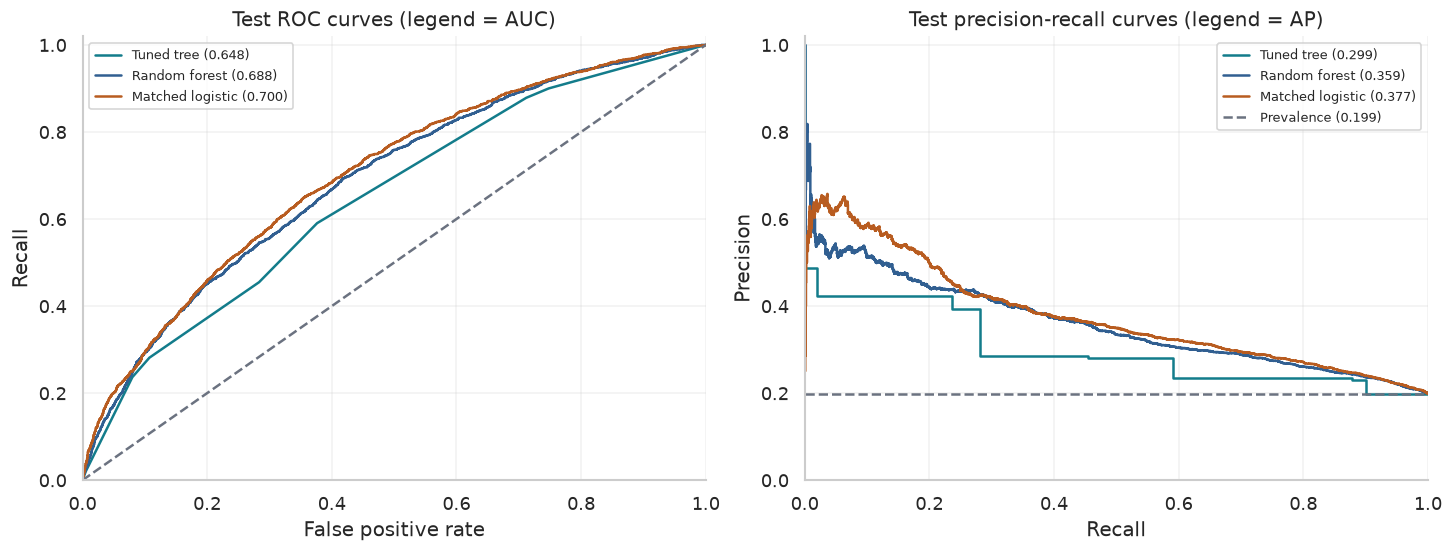

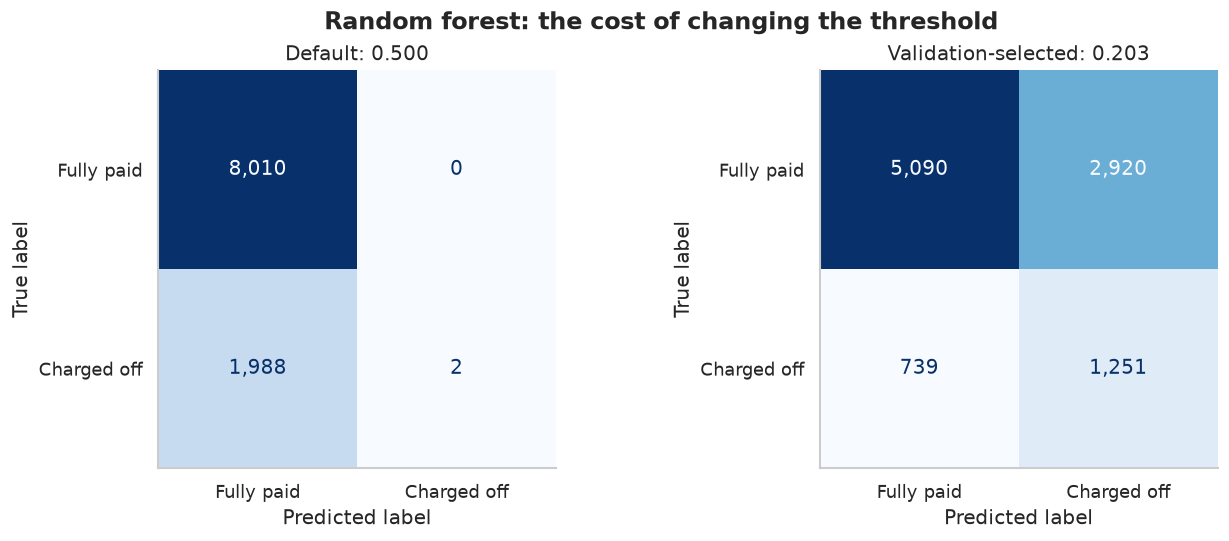

In [10]:
thresholds={};validation_rows=[]
for name,model in fitted.items():
    score=model.predict_proba(X_val)[:,1]
    chosen,table=choose_threshold(y_val,score,.5)
    thresholds[name]=chosen
    validation_rows.append(classification_metrics(name,y_val,score,chosen,"Validation-selected"))
validation_results=pd.DataFrame(validation_rows)
show_table(validation_results[["Model","Threshold","Precision","Recall","F1","ROC-AUC"]])
validation_results.to_csv(OUTPUT_DIR/"validation_thresholds.csv",index=False)
print("Settings and thresholds are frozen. Evaluating the test split now.")

rows=[];gaps=[];test_scores={}
for name,model in fitted.items():
    score=model.predict_proba(X_test)[:,1];test_scores[name]=score
    for rule,threshold in [("default",.5),("selected",thresholds[name])]:
        row=classification_metrics(name,y_test,score,threshold,rule)
        row.update({"Log loss":log_loss(y_test,score,labels=[0,1]),"Brier":brier_score_loss(y_test,score)})
        rows.append(row)
    for split,frame,target in [("Training",X_fit,y_fit),("Validation",X_val,y_val),("Test",X_test,y_test)]:
        split_score=model.predict_proba(frame)[:,1]
        gaps.append({"Model":name,"Split":split,"ROC-AUC":roc_auc_score(target,split_score),
            "Average precision":average_precision_score(target,split_score),"Log loss":log_loss(target,split_score,labels=[0,1])})
baseline=np.full(len(y_test),y_fit.mean())
row=classification_metrics("Majority baseline",y_test,baseline,.5,"default")
row.update({"Log loss":log_loss(y_test,baseline,labels=[0,1]),"Brier":brier_score_loss(y_test,baseline)})
rows.append(row)
test_results=pd.DataFrame(rows);gap_table=pd.DataFrame(gaps)
show_table(test_results[["Model","Rule","Accuracy","Precision","Recall","F1","ROC-AUC","Average precision"]])
show_table(test_results.loc[test_results.Rule.eq("selected"),["Model","Threshold","TP","FP","FN","TN","Log loss","Brier"]])
show_table(gap_table)
test_results.to_csv(OUTPUT_DIR/"test_metrics.csv",index=False)
gap_table.to_csv(OUTPUT_DIR/"generalization_scores.csv",index=False)
pd.DataFrame({"source_row":loans.loc[X_test.index,"source_row"].to_numpy(),"observed_charged_off":y_test.to_numpy(),
    "predicted_probability":test_scores[selected_name],"selected_prediction":(test_scores[selected_name]>=thresholds[selected_name]).astype(int)}).to_csv(OUTPUT_DIR/"test_predictions.csv",index=False)
plot_ranking(y_test,{name:test_scores[name] for name in ["Tuned tree","Random forest","Matched logistic"]},"figure_5_test_ranking")
plot_confusions(y_test,test_scores[selected_name],.5,thresholds[selected_name],selected_name,"figure_6_test_confusions")

## 8. What I Learned, Limits, and Next Steps

The results-based summary below reflects the final model evaluations. I will review the training-versus-cross-validation generalization gap, comparative ROC/PR ranking curves, and explicit error counts (false positives vs. missed charge-offs) before deciding which insights to carry forward into Milestone One.

## Week 6 Findings

Cross-validation on the training set selected the **Random Forest** over the tuned decision tree. Its test ROC-AUC reached **0.688**, compared to **0.700** for the matched logistic regression benchmark fit on the exact same 8,000 loan subset. 

### Classification Performance
At the validation-selected decision threshold of **0.203**:
* **Recall:** 62.9% (caught 1,251 charged-off loans; missed 739)
* **Precision:** 30.0% (flagged 2,920 fully paid loans)
* **F1 Score:** 0.406

### Overfitting Diagnostics and Interpretability
The unconstrained tree's performance highlights the critical need for regularization: it achieved a perfect mean training ROC-AUC of **1.000**, but collapsed to **0.549** in cross-validation. That massive generalization gap matters far more than a perfect training score, reinforcing why strict depth, leaf size, and split controls are necessary to prevent nodes from fitting to tiny clusters of loans.

For the random forest, the top three features by validation permutation importance were `term`, `fico_range_low`, and `dti`. However, I would carefully inspect their raw score magnitudes and repeat-to-repeat variation before declaring them definitive drivers, and I would certainly not interpret them as causal mechanisms for default.

### Scope and Next Steps
For the capstone, I will align these tree-based models with Week 5's SVM results only after verifying that their source-row manifests match row-for-row. To make these findings production-ready, I still need an out-of-time evaluation on later loan vintages, a threshold calibrated to actual review capacity or financial cost, and a fairness check across key borrower demographics. The current results provide a strong basis for academic comparison and human analyst review, not an automated approval or rejection system.

In [12]:
run_summary={"week":6,"dataset_version":DATASET_VERSION,"sample_rows":len(loans),
    "source_rows":source_info["rows_scanned"],"seed":SEED,"python":sys.version.split()[0],
    "pandas":pd.__version__,"sklearn":sklearn.__version__,
    "sample_source_rows_sha256":hashlib.sha256(loans["source_row"].to_numpy(dtype="int64").tobytes()).hexdigest()}
run_summary.update({"target":"charged_off","model_training_rows":len(y_fit),"validation_rows":len(y_val),"test_rows":len(y_test),"selected_model":selected_name,"tree_parameters":tree_search.best_params_,"forest_parameters":forest_search.best_params_,"threshold":thresholds[selected_name],"threshold_objective":"validation F1 on prespecified quantile grid","root_information_gain_bits":information_gain,"cv_folds":CV_FOLDS})
(OUTPUT_DIR/"run_summary.json").write_text(json.dumps(run_summary,indent=2))
(OUTPUT_DIR/"milestone_takeaway.md").write_text(takeaway,encoding="utf-8")
print("Saved figures, tables, settings, and the computed takeaway to",OUTPUT_DIR)

Saved figures, tables, settings, and the computed takeaway to week6_outputs
